# **Functions of project Topolino**

This notebook contains a collection of functions that are used in the other notebooks. The functions are organized into sections based on their purpose. Each function is documented with a brief description of its purpose and its inputs and outputs.

In [1]:
from topolino import *
import numpy as np
import matplotlib.pyplot as plt

# `propTF`

This function simulates free-space light propagation over a distance $z\_m$ using the transfer function approach to the Fresnel diffraction approximation.

**Key Steps Performed**

* **Grid Generation:** Calculates the spatial sampling interval $dx$ from the total window size $L\_m$ and computes the corresponding spatial frequencies ($f_x, f_y$).
* **Transfer Function Construction:** Evaluates the Fresnel transfer function in the frequency domain, $H(f_x, f_y) = \exp\!\left[-i \pi \lambda z (f_x^2 + f_y^2)\right]$, which applies a quadratic phase shift proportional to the wavelength $\lambda\_m$, propagation distance $z\_m$, and spatial frequency magnitude.
* **Field Propagation:** Transforms the input complex field $E_{\text{in}}$ into Fourier space, multiplies it by the transfer function $H$, and computes the inverse Fourier transform to return the output optical field $E_{\text{out}}$.

```python 

def propTF(uin_V_m, L_m, lambda_m, z_m):
    """
    Parameters
    ----------
    uin_V_m : numpy.ndarray, shape (M,)
        Complex input field amplitude [V/m].
    L_m : float
        Physical length of the sampling window [m].
    lambda_m : float
        Optical wavelength [m].
    z_m : float
        Propagation distance [m].

    Returns
    -------
    uout_V_m : numpy.ndarray, shape (M,)
        Complex output field amplitude at distance ``z_m`` [V/m].

    Notes
    -----
    The TF method assumes the Fresnel approximation is valid and that the
    output window size equals the input window size (``L_m``).  It is
    accurate when the sampling criterion
    ``|z_m| >= L_m^2 / (M * lambda_m)`` is satisfied.
    """
    M = uin_V_m.size
    dx_m = L_m / M

    fx_1_m = np.linspace(-1 / (2 * dx_m), 1 / (2 * dx_m) - (1 / L_m), M)

    H = np.exp(-1j * np.pi * lambda_m * z_m * (fx_1_m**2))
    H = np.fft.fftshift(H)

    Uin_V_m = np.fft.fft(np.fft.fftshift(uin_V_m))
    Uout_V_m = H * Uin_V_m
    uout_V_m = np.fft.ifftshift(np.fft.ifft(Uout_V_m))
    return uout_V_m

# Example use cases:

**Beam‑Size vs. Propagation Distance**

For each distance we compute the RMS beam size from the intensity moments and store the results.  

In [14]:
wavelength_m = 500e-9          # 500 nm
dx_m         = 1e-6           # transverse sampling (1 µm)
Dx_m         = 1.0            # transverse window (1 m)

x_m = np.linspace(-Dx_m/2, Dx_m/2, int(Dx_m/dx_m) + 1)

sigma0_m = 50e-6               # 50 µm
I0 = np.exp(-(x_m**2) / (2 * sigma0_m**2))   # intensity profile
E0 = np.sqrt(I0)               # field amplitude (real‑valued)

Z_m = np.linspace(-1.1, 1.1, 100)   # from –1.1 m to +1.1 m

sim_beam_sizes_m = []
Ixz = np.zeros((len(Z_m), len(x_m)))   # normalized intensity vs (z,x)

for idx, z in enumerate(Z_m):
    Ez = propTF(E0, Dx_m, wavelength_m, z)
    Iz = np.abs(Ez)**2

    # Normalise each slice for visualisation (max = 1)
    Iz_norm = Iz / Iz.max()
    Ixz[idx, :] = Iz_norm

    # RMS beam size from intensity‑weighted second moment
    x_mean = np.sum(x_m * Iz) / np.sum(Iz)
    sigma_z = np.sqrt(np.sum((x_m - x_mean)**2 * Iz) / np.sum(Iz))
    sim_beam_sizes_m.append(sigma_z)

sim_beam_sizes_m = np.array(sim_beam_sizes_m)   

**Theoretical Diffraction‑Limited Beam Size** 
For a Gaussian with RMS waist \(\sigma_{0}\) the paraxial law is  

$$
\sigma(z)=\sqrt{\sigma_{0}^{2}+(\theta\,z)^{2}},\qquad
\theta=\frac{\lambda}{4\pi\,\sigma_{0}}
$$

where $\theta$ is the RMS divergence (rad).  
We overlay the analytical curve on the simulated data.  


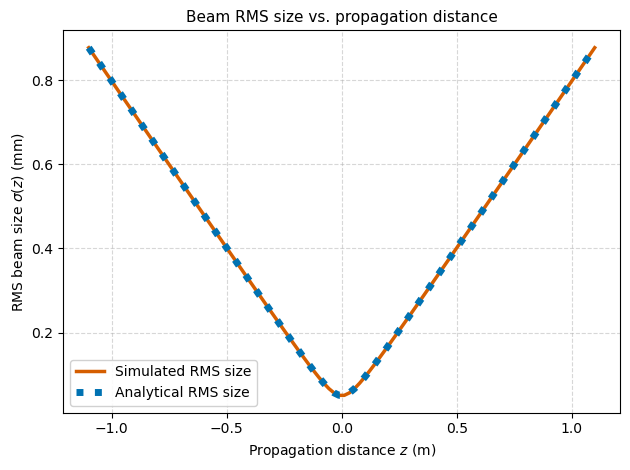

In [15]:
#  Analytical RMS beam size 
theta_rad = wavelength_m / (4 * np.pi * sigma0_m)    # RMS divergence (rad)
sigma_th_m = np.sqrt(sigma0_m**2 + (theta_rad * Z_m)**2)


plt.plot(Z_m, np.array(sim_beam_sizes_m) * 1e3,
         label='Simulated RMS size', color='#D55E00', linewidth=2.5)

plt.plot(Z_m, np.array(sigma_th_m) * 1e3,
         ':', label='Analytical RMS size', color='#0072B2', linewidth=5)

plt.xlabel('Propagation distance $z$ (m)', fontsize=10)
plt.ylabel('RMS beam size $\\sigma(z)$ (mm)', fontsize=10)
plt.title('Beam RMS size vs. propagation distance', fontsize=11)
plt.grid(True, ls='--', alpha=0.5)
plt.legend(framealpha=0.9)
plt.tight_layout()
plt.show()

**Full 2‑D Beam Evolution (X–Z Diagram)**

Compute the intensity for many propagation distances (negative → positive) and display it with `imshow`.  


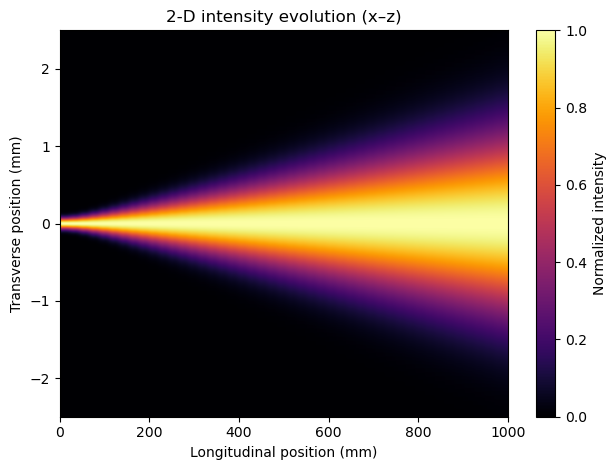

In [7]:
im = plt.imshow(np.transpose(Ixz),
                extent=[Z_m[0]*1e3, Z_m[-1]*1e3, x_m[0]*1e3, x_m[-1]*1e3],
                aspect='auto',
                cmap='inferno')
plt.ylim([-2.5, 2.5])  # Updated bounds in mm (-0.0025 m to 0.0025 m)
plt.xlabel("Longitudinal position (mm)")
plt.ylabel("Transverse position (mm)")
plt.xlim([0, 1000])
plt.title("2-D intensity evolution (x–z)")
plt.colorbar(im, label='Normalized intensity')
plt.tight_layout()
plt.show()